# 1. - Definición problema:

El objetivo de este análisis es identificar patrones que indiquen si un cliente puede tener dificultades para devolver un préstamo, utilizando técnicas de Análisis Exploratorio de Datos (EDA). Esto es crucial para el banco porque:

- Evitar el rechazo de clientes solventes: Garantizar que los clientes con capacidad de pago no sean rechazados, maximizando los ingresos del banco.
- Minimizar el riesgo de incumplimiento: Detectar características de clientes más propensos a no devolver el préstamo (TARGET=1). Esto va a ser lo fundamental ya que es lo que conlleva un mayor riesgo para el banco.


## 1.1. - Comprobaciones sistema, librerias, datasets

In [1]:
# Comprobamos la verisión de python con la que estamos trabajando y donde se está ejecutando 
import sys

print(sys.version)
print(sys.path)
print("---")
print(sys.executable)

3.8.20 (default, Oct  3 2024, 10:25:41) 
[Clang 14.0.6 ]
['/opt/miniconda3/envs/credit-risk-verify/lib/python38.zip', '/opt/miniconda3/envs/credit-risk-verify/lib/python3.8', '/opt/miniconda3/envs/credit-risk-verify/lib/python3.8/lib-dynload', '', '/opt/miniconda3/envs/credit-risk-verify/lib/python3.8/site-packages']
---
/opt/miniconda3/envs/credit-risk-verify/bin/python


In [2]:
## Importación librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

from rich.console import Console
from rich.table import Table

sys.path.append('../src')  # Asegúrate de que ../src es la carpeta donde está Funciones_Ayuda.py
import funciones as f  # Ahora debería importarse correctamente
sys.path.remove('../src') ### MÓDULO CON FUNCIONES QUE VOY A USAR


warnings.filterwarnings("ignore")

## Configuro la visualización de mis datasets
pd.set_option('display.max_columns', 500)
pd.set_option('display.max_rows', 500)

In [3]:
### Leer el dataset y un primer vistazo 
df_loan_apli = pd.read_csv('../data/raw_data/application_data.csv')
df_loan_apli.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

### Variables a futuro

En el dataset proporcionado no parece haber variables que podamos catalogar estrictamente como a futuro, es decir, aquellas cuya información aún no está disponible y solo podría conocerse en un momento posterior. Si bien algunas variables pueden actualizarse con el tiempo, como las relacionadas con consultas a burós de crédito o cambios en el registro del cliente, estas se basan en información histórica o actual y no representan eventos desconocidos que ocurrirán en el futuro. Por lo tanto, aunque algunas variables tienen potencial para predecir comportamientos futuros, no hay evidencia de que existan variables específicamente diseñadas para capturar datos que aún no se han generado.

# 2. - Análisis general de la tabla

In [4]:
print(df_loan_apli.shape, df_loan_apli.drop_duplicates().shape)

(307511, 122) (307511, 122)


In [5]:
print(f'Distribución de clases: ')
df_loan_apli.dtypes.sort_values().to_frame('features').groupby('features').size().to_frame('quantity').reset_index()
    ## necesito transformarlo en un vec col con to_frame para poder agrupar por el nombre de la col 

Distribución de clases: 


,features,quantity
0,int64,41
1,float64,65
2,object,16


In [6]:
f.analizar_variables(df_loan_apli)

                                               Análisis de Variables                                               
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Variable                     ┃ Tipo Actual ┃ Tipo Potencial ┃ Ejemplos Únicos                                   ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ SK_ID_CURR                   │ int64       │ ID             │ 100002, 100003, 100004, 100006, 100007...         │
│ TARGET                       │ int64       │ Booleana       │ 1, 0                                              │
│ NAME_CONTRACT_TYPE           │ object      │ Booleana       │ Cash loans, Revolving loans                       │
│ CODE_GENDER                  │ object      │ Categoría      │ M, F, XNA                                         │
│ FLAG_OWN_CAR                 │ object      │ Booleana       │ N, Y                                              │
│ FLAG_OWN_REALTY              │ object      │ Booleana       │ Y, N                                              │
│ CNT_CHILDREN                 │ int64       │ Categoría      │ 0, 1, 2, 3, 4...                                  │
│ AMT_INCOME_TOTAL             │ float64     │ Numérica       │ 202500.0, 270000.0, 67500.0, 135000.0,            │
│                              │             │                │ 121500.0...                                       │
│ AMT_CREDIT                   │ float64     │ Numérica       │ 406597.5, 1293502.5, 135000.0, 312682.5,          │
│                              │             │                │ 513000.0...                                       │
│ AMT_ANNUITY                  │ float64     │ Numérica       │ 24700.5, 35698.5, 6750.0, 29686.5, 21865.5...     │
│ AMT_GOODS_PRICE              │ float64     │ Numérica       │ 351000.0, 1129500.0, 135000.0, 297000.0,          │
│                              │             │                │ 513000.0...                                       │
│ NAME_TYPE_SUITE              │ object      │ Categoría      │ Unaccompanied, Family, Spouse, partner, Children, │
│                              │             │                │ Other_A...                                        │
│ NAME_INCOME_TYPE             │ object      │ Categoría      │ Working, State servant, Commercial associate,     │
│                              │             │                │ Pensioner, Unemployed...                          │
│ NAME_EDUCATION_TYPE          │ object      │ Categoría      │ Secondary / secondary special, Higher education,  │
│                              │             │                │ Incomplete higher, Lower secondary, Academic      │
│                              │             │                │ degree                                            │
│ NAME_FAMILY_STATUS           │ object      │ Categoría      │ Single / not married, Married, Civil marriage,    │
│                              │             │                │ Widow, Separated...                               │
│ NAME_HOUSING_TYPE            │ object      │ Categoría      │ House / apartment, Rented apartment, With         │
│                              │             │                │ parents, Municipal apartment, Office apartment... │
│ REGION_POPULATION_RELATIVE   │ float64     │ Categoría      │ 0.018801, 0.0035409999999999, 0.010032, 0.008019, │
│                              │             │                │ 0.028663...                                       │
│ DAYS_BIRTH                   │ int64       │ Numérica       │ -9461, -16765, -19046, -19005, -19932...          │
│ DAYS_EMPLOYED                │ int64       │ Numérica       │ -637, -1188, -225, -3039, -3038...                │
│ DAYS_REGISTRATION            │ float64     │ Numérica       │ -3648.0, -1186.0, -4260.0, -9833.0, -4311.0...    │
│ DAYS_ID_PUBLISH              │ int64       │ Numérica 

## Inferencia sobre la tabla

Con esto puedo analizar y determinar el tipo real de cada una de las variables en mi dataset. No se trata únicamente de observar el tipo de dato actual (como int64, float64 o object), sino de comprender a profundidad qué tipo de información representa cada variable en el contexto de mi análisis.

La función evalua cada columna según su distribución de valores únicos y su relación con el total de filas del dataset.
Se determina un tipo potencial para cada variable:
- Booleana: Si la variable tiene únicamente dos valores únicos.
- Categoría: Si el número de valores únicos es bajo (por ejemplo, menos de 100), indicando que representa clases.
- ID: Si cada valor es único, lo que sugiere que la variable es un identificador.
- Numérica: Si la variable contiene valores continuos con una alta cardinalidad.

# 2.1. - Exploración de la variable objetivo y tratamiento 

In [7]:
df_target_distribution = df_loan_apli['TARGET'].to_frame('Solvency_label').value_counts().to_frame('Quantity').reset_index()
df_target_distribution

,Solvency_label,Quantity
0,0,282686
1,1,24825


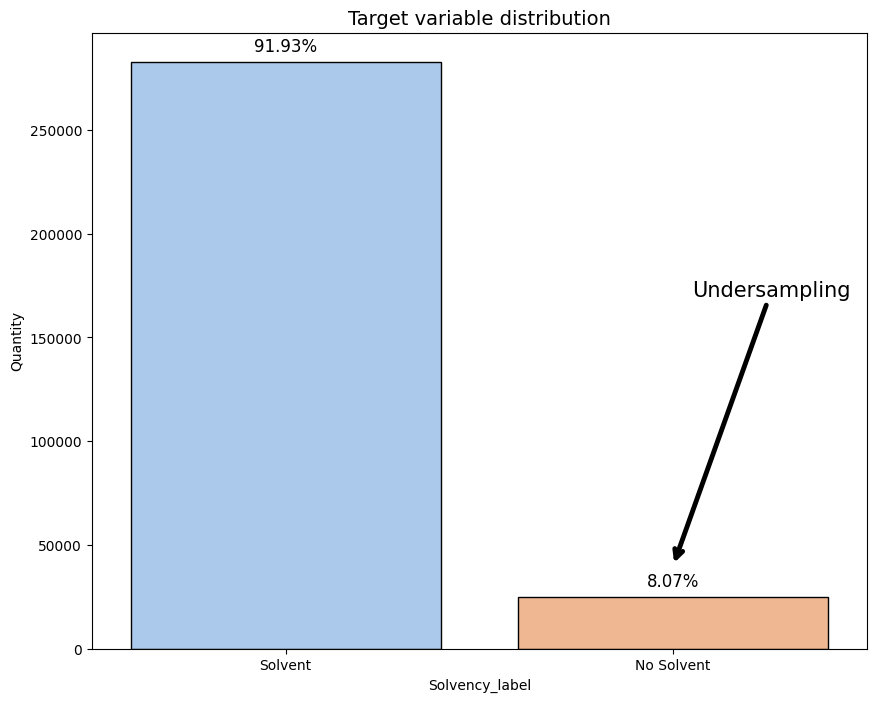

In [8]:
plt.figure(figsize=(10,8))

(sns.barplot(x=df_target_distribution.Solvency_label, 
             y=df_target_distribution.Quantity, 
             palette='pastel', edgecolor='black'))

# Añadir etiquetas y título
plt.title(f'Target variable distribution', fontsize=14)
# Cambiar las etiquetas del eje X
plt.xticks(ticks=[0, 1], labels=['Solvent', 'No Solvent'])

# Añadir ana anotación con flecha dentro del gráfico 
plt.annotate('Undersampling',
             xy= (1, 40000), xytext= (1.05, 170000), fontsize=15,
             arrowprops=dict(
                 arrowstyle = '->',
                 color = 'black',
                 lw = 3.5))     ## ancho flecha

total = df_target_distribution.Quantity.sum()
for i, value in enumerate(df_target_distribution.Quantity): ## con enumerate() itero sobre un objeto añadiendo un contador (índice)
    percentage = f"{(value / total) * 100:.2f}%"  # Calcular porcentaje
    plt.text(i, value + 5000, percentage, 
             ha='center', fontsize=12, color='black')  # Añadir texto

plt.show()

La distribución de la variable objetivo muestra un marcado desequilibrio, con el 91.93% de los casos pertenecientes a la clase "Solvente" (0) y solo el 8.07% a la clase "No solvente" (1). Este desequilibrio implica que el dataset está desbalanceado, lo cual puede tener un impacto significativo en el rendimiento de los modelos predictivos.

**Implicaciones:**
- Rendimiento del modelo: Los modelos de machine learning tienden a **sesgarse hacia la clase mayoritaria, en este caso, "Solvente"**. Esto puede resultar en altas métricas de precisión global, pero con un desempeño deficiente en la predicción de la clase minoritaria ("No solvente"), que generalmente es la más relevante en un análisis crediticio.
- Métricas inadecuadas: Métricas comunes como **la precisión pueden dar una falsa sensación de buen rendimiento** debido a la alta proporción de la clase mayoritaria. En este caso, habría que buscar otras métricas que se ajusten al desbalance.
- Riesgos operativos: Si el modelo es capaz de identificar a los clientes solventes al 100% pero no a los no solventes, **su utilidad es de 0**. Ningún banco querría este producto, ya que el reisgo de financiación, que es lo que se quiere evaluar, no es sería capaz de determinarlo.

**Posibles medidas a tomar:**
- Utilizar métricas adecuadas: Optar por **métricas sensibles al desbalance**, como el F1-score, la métrica de recall para la clase minoritaria, o la curva ROC-AUC. Esto es lo más sencillo de hacer y más eficiente
- Técnicas de balanceo del dataset: 
    - Sobremuestreo de la clase minoritaria: Crear copias sintéticas de la clase "No solvente" utilizando técnicas como SMOTE (Synthetic Minority Over-sampling Technique).
    - Submuestreo de la clase mayoritaria: Reducir el número de instancias de la clase "Solvente" para equilibrar la proporción.
- Ajustar pesos en el modelo: Asignar un mayor peso a la clase minoritaria en algoritmos que permiten ponderaciones, como árboles de decisión o modelos de clasificación basados en gradiente.
- Algoritmos robustos al desbalance: Emplear modelos que manejan de forma nativa el desequilibrio, como Gradient Boosting Machines o Random Forest con parámetros específicos para manejar clases desbalanceadas.
- Segmentación adicional: Dividir el dataset en grupos con características comunes y analizar si el desbalance es uniforme o se concentra en ciertos segmentos.

Estas medidas permitirán abordar el problema del desbalance y mejorar la capacidad del modelo para predecir con precisión ambas clases, especialmente la "No solvente", que suele ser la de mayor interés en este tipo de análisis.

# 3. - Selección de threshold por filas y columnas para eliminar los valores missing

## 3.1. - Nulos por columnas

In [9]:
df_nulos_col = df_loan_apli.isnull().sum().to_frame('Nulos').sort_values(by='Nulos', ascending=False).reset_index(names='Variables')
df_nulos_col['Porcentaje'] = (df_nulos_col['Nulos'] * 100 / df_loan_apli.shape[0]).round(2)
df_nulos_col[df_nulos_col['Nulos'] > 0]

,Variables,Nulos,Porcentaje
0,COMMONAREA_MEDI,214865,69.87
1,COMMONAREA_AVG,214865,69.87
2,COMMONAREA_MODE,214865,69.87
3,NONLIVINGAPARTMENTS_MODE,213514,69.43
4,NONLIVINGAPARTMENTS_AVG,213514,69.43
5,NONLIVINGAPARTMENTS_MEDI,213514,69.43
6,FONDKAPREMONT_MODE,210295,68.39
7,LIVINGAPARTMENTS_MODE,210199,68.35
8,LIVINGAPARTMENTS_AVG,210199,68.35
9,LIVINGAPARTMENTS_MEDI,210199,68.35


In [10]:
# Identificar columnas con más de 100 valores nulos
condicion = df_loan_apli.isnull().sum() > 100
# Obtener los nombres de las columnas que cumplen la condición
columnas_nulas = df_loan_apli.columns[condicion].tolist()

# Mostrar los nombres de las columnas
print(columnas_nulas)


['AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'OWN_CAR_AGE', 'OCCUPATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMAX_AVG', 'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG', 'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG', 'APARTMENTS_MODE', 'BASEMENTAREA_MODE', 'YEARS_BEGINEXPLUATATION_MODE', 'YEARS_BUILD_MODE', 'COMMONAREA_MODE', 'ELEVATORS_MODE', 'ENTRANCES_MODE', 'FLOORSMAX_MODE', 'FLOORSMIN_MODE', 'LANDAREA_MODE', 'LIVINGAPARTMENTS_MODE', 'LIVINGAREA_MODE', 'NONLIVINGAPARTMENTS_MODE', 'NONLIVINGAREA_MODE', 'APARTMENTS_MEDI', 'BASEMENTAREA_MEDI', 'YEARS_BEGINEXPLUATATION_MEDI', 'YEARS_BUILD_MEDI', 'COMMONAREA_MEDI', 'ELEVATORS_MEDI', 'ENTRANCES_MEDI', 'FLOORSMAX_MEDI', 'FLOORSMIN_MEDI', 'LANDAREA_MEDI', 'LIVINGAPARTMENTS_MEDI', 'LIVINGAREA_MEDI', 'NONLIVINGAPARTMENTS_MEDI', 'NONLIVINGAREA_MEDI', 'FONDKAPREM

## 3.1.1. - Analizar la relación de nulos con la variable objetivo

In [11]:
# Crear una lista vacía para almacenar los resultados
lista_resultados = []

# Iterar sobre las columnas con valores nulos
for i in columnas_nulas:
    resultado = f.calcular_porcentaje_target(df_loan_apli, i)
    lista_resultados.append(resultado)


In [12]:
## Como tenemos una tupla con sublistas formadas por 2 elementos, podemos transformar este tupla a
## un df simplemente aplicando 'pd.DataFrame', ya que lo que tenmos es una matriz formada por:
    ## nsublistas --> nfilas
    ## nelementos en cada sublista --> valor de variable y de porcentaje
    ## dim: n x 2

df_porcentajes = pd.DataFrame(lista_resultados, columns=['Variables', 'Porcentaje TARGET=1'])

df_nulos_col_target = df_nulos_col.merge(df_porcentajes, on='Variables', how='left')
df_nulos_col_target[df_nulos_col_target['Nulos'] > 100]

,Variables,Nulos,Porcentaje,Porcentaje TARGET=1
0,COMMONAREA_MEDI,214865,69.87,8.57
1,COMMONAREA_AVG,214865,69.87,8.57
2,COMMONAREA_MODE,214865,69.87,8.57
3,NONLIVINGAPARTMENTS_MODE,213514,69.43,8.58
4,NONLIVINGAPARTMENTS_AVG,213514,69.43,8.58
5,NONLIVINGAPARTMENTS_MEDI,213514,69.43,8.58
6,FONDKAPREMONT_MODE,210295,68.39,8.62
7,LIVINGAPARTMENTS_MODE,210199,68.35,8.62
8,LIVINGAPARTMENTS_AVG,210199,68.35,8.62
9,LIVINGAPARTMENTS_MEDI,210199,68.35,8.62


## Inferencia Tabla Valores nulos 

La información en la que me voy a basar para hacer determinar el threshold va a ser:
- La cantidad de nulos 
- El porcentaje TARGET=1 cuando solo usamos esos valores nulos 

Teniendo en cuneta que la varible objetivo con TARGET = 1 representaba un 8.07% de los casos.Podemos ver que hay muchas columnas que aparte de tener una gran cantidad de nulos, no aportan ninguna información ya que la distribución se mantiene muy similar, es decir, que seguramente esté determinada por la alaetoriedad. 

Con esto voy a determinar el umbaral en un 66% de nulos porque apartir de ahí la distribución del target enmpieza a ser intersente guardarla. Quiero guardar la varible: 'OWN_CAR_AGE' porque creo que podría ser relevante

## 3.1.2. - Determinar un threshold en función del análisis realizado

In [13]:
## Lo he determinado he determinado en función de la cnatidad de nulos y la capacidad de poder predecri
## la variable objetivo 

threshold = 66
list_vars_not_null = list(df_nulos_col[df_nulos_col['Porcentaje']<threshold]['Variables'])
deleted_variables = list(df_nulos_col[df_nulos_col['Porcentaje']>threshold]['Variables'])

df_loan_filt_null = df_loan_apli.loc[:, list_vars_not_null]
print(df_loan_filt_null.shape)
df_loan_filt_null

(307511, 106)


,OWN_CAR_AGE,LANDAREA_MEDI,LANDAREA_MODE,LANDAREA_AVG,BASEMENTAREA_MEDI,BASEMENTAREA_AVG,BASEMENTAREA_MODE,EXT_SOURCE_1,NONLIVINGAREA_MODE,NONLIVINGAREA_AVG,NONLIVINGAREA_MEDI,ELEVATORS_MEDI,ELEVATORS_AVG,ELEVATORS_MODE,WALLSMATERIAL_MODE,APARTMENTS_MEDI,APARTMENTS_AVG,APARTMENTS_MODE,ENTRANCES_MEDI,ENTRANCES_AVG,ENTRANCES_MODE,LIVINGAREA_AVG,LIVINGAREA_MODE,LIVINGAREA_MEDI,HOUSETYPE_MODE,FLOORSMAX_MODE,FLOORSMAX_MEDI,FLOORSMAX_AVG,YEARS_BEGINEXPLUATATION_MODE,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BEGINEXPLUATATION_AVG,TOTALAREA_MODE,EMERGENCYSTATE_MODE,OCCUPATION_TYPE,EXT_SOURCE_3,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,NAME_TYPE_SUITE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,EXT_SOURCE_2,AMT_GOODS_PRICE,AMT_ANNUITY,CNT_FAM_MEMBERS,DAYS_LAST_PHONE_CHANGE,CNT_CHILDREN,FLAG_DOCUMENT_8,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_9,FLAG_DOCUMENT_21,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_OWN_REALTY,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_12,AMT_CREDIT,AMT_INCOME_TOTAL,FLAG_PHONE,LIVE_CITY_NOT_WORK_CITY,REG_CITY_NOT_WORK_CITY,TARGET,REG_CITY_NOT_LIVE_CITY,LIVE_REGION_NOT_WORK_REGION,REG_REGION_NOT_WORK_REGION,REG_REGION_NOT_LIVE_REGION,HOUR_APPR_PROCESS_START,WEEKDAY_APPR_PROCESS_START,REGION_RATING_CLIENT_W_CITY,REGION_RATING_CLIENT,FLAG_EMAIL,FLAG_CONT_MOBILE,ORGANIZATION_TYPE,FLAG_WORK_PHONE,FLAG_EMP_PHONE,FLAG_MOBIL,DAYS_ID_PUBLISH,DAYS_REGISTRATION,DAYS_EMPLOYED,DAYS_BIRTH,REGION_POPULATION_RELATIVE,NAME_HOUSING_TYPE,NAME_FAMILY_STATUS,NAME_EDUCATION_TYPE,NAME_INCOME_TYPE,SK_ID_CURR
0,NaN,0.0375,0.0377,0.0369,0.0369,0.0369,0.0383,0.083037,0.0000,0.0000,0.0000,0.00,0.00,0.0000,"Stone, brick",0.0250,0.0247,0.0252,0.0690,0.0690,0.0690,0.0190,0.0198,0.0193,block of flats,0.0833,0.0833,0.0833,0.9722,0.9722,0.9722,0.0149,No,Laborers,0.139376,0.0,0.0,0.0,0.0,0.0,1.0,Unaccompanied,2.0,2.0,2.0,2.0,0.262949,351000.0,24700.5,1.0,-1134.0,0,0,Cash loans,M,N,0,1,0,0,0,0,0,0,0,0,Y,0,0,0,0,0,0,0,0,0,406597.5,202500.0,1,0,0,1,0,0,0,0,10,WEDNESDAY,2,2,0,1,Business Entity Type 3,0,1,1,-2120,-3648.0,-637,-9461,0.018801,House / apartment,Single / not married,Secondary / secondary special,Working,100002
1,NaN,0.0132,0.0128,0.0130,0.0529,0.0529,0.0538,0.311267,0.0000,0.0098,0.0100,0.08,0.08,0.0806,Block,0.0968,0.0959,0.0924,0.0345,0.0345,0.0345,0.0549,0.0554,0.0558,block of flats,0.2917,0.2917,0.2917,0.9851,0.9851,0.9851,0.0714,No,Core staff,NaN,0.0,0.0,0.0,0.0,0.0,0.0,Family,1.0,0.0,1.0,0.0,0.622246,1129500.0,35698.5,2.0,-828.0,0,0,Cash loans,F,N,0,1,0,0,0,0,0,0,0,0,N,0,0,0,0,0,0,0,0,0,1293502.5,270000.0,1,0,0,0,0,0,0,0,11,MONDAY,1,1,0,1,School,0,1,1,-291,-1186.0,-1188,-16765,0.003541,House / apartment,Married,Higher education,State servant,100003
2,26.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Laborers,0.729567,0.0,0.0,0.0,0.0,0.0,0.0,Unaccompanied,0.0,0.0,0.0,0.0,0.555912,135000.0,6750.0,1.0,-815.0,0,0,Revolving loans,M,Y,0,0,0,0,0,0,0,0,0,0,Y,0,0,0,0,0,0,0,0,0,135000.0,67500.0,1,0,0,0,0,0,0,0,9,MONDAY,2,2,0,1,Government,1,1,1,-2531,-4260.0,-225,-19046,0.010032,House / apartment,Single / not married,Secondary / secondary special,Working,100004
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Laborers,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Unaccompanied,2.0,0.0,2.0,0.0,0.650442,297000.0,29686.5,2.0,-617.0,0,0,Cash loans,F,N,0,1,0,0,0,0,0,0,0,0,Y,0,0,0,0,0,0,0,0,0,312682.5,135000.0,0,0,0,0,0,0,0,0,17,WEDNESDAY,2,2,0,1,Business Entity Type 3,0,1,1,-2437,-9833.0,-3039,-19005,0.008019,House / apartment,Civ

# 3.2. - Nulos por filas

In [14]:
## Ahora vamos a realizar un proceso parecido con los valore faltantes en las filas 
series_null_rows = df_loan_apli.isnull().sum(axis=1).sort_values(ascending=False)
print(series_null_rows.shape)
print(series_null_rows.head())

(307511,)
185713    61
133770    61
197736    61
116937    61
269492    61
dtype: int64


In [15]:
df_null_filas = pd.DataFrame(series_null_rows, columns=['Nulos_filas'])  
df_null_filas['Target'] = df_loan_apli['TARGET'].copy()
df_null_filas['Porcentaje_filas'] = df_null_filas['Nulos_filas']/df_loan_apli.shape[1]
df_null_filas

,Nulos_filas,Target,Porcentaje_filas
185713,61,0,0.5
133770,61,0,0.5
197736,61,0,0.5
116937,61,0,0.5
269492,61,0,0.5
...,...,...,...
129942,0,0,0.0
129929,0,0,0.0
129924,0,0,0.0
129911,0,0,0.0


# 4. - Tipos: Variables categóricas y numéricas

In [16]:
## Primer vistazo para saber que clases tengo en mi dataset 
# Las que voy a tener que analizar principalmente son las clases obejto para determinar si son 
    # Binarias 
    # Categóricas
        # Nominales 
        # Ordinales --> podría valorar si transformarlas a numércias 
    # Variables de texto libre / con alta cardinalidad
    # Fechas / Numéricas puestas como string
df_loan_filt_null.dtypes.sort_values().to_frame('Clases').groupby('Clases').size().to_frame('Conteo').reset_index()

,Clases,Conteo
0,int64,41
1,float64,50
2,object,15


## 4.1. - VARIABLES OBJETO

Voy a empezar clasificando las variables 'object', confirmando si son categóricas o no, lo más probable es que la mayoría lo sean.

In [17]:
#### Paso 1: Determinar posibles categóricas y variables de altas dimensiones 

lista_var_categoricas , lista_var_altas_dimensiones = f.dame_variables_categoricas(df_loan_filt_null)

df_categoricas_unicos = pd.DataFrame(df_loan_filt_null[lista_var_categoricas].nunique(), columns=['n_unicos']).reset_index(names='variables')
print(len(lista_var_categoricas))
df_categoricas_unicos
### Todas las columnas tipo objeto, se ve claramente que son categóricas 

15


,variables,n_unicos
0,WALLSMATERIAL_MODE,7
1,HOUSETYPE_MODE,3
2,EMERGENCYSTATE_MODE,2
3,OCCUPATION_TYPE,18
4,NAME_TYPE_SUITE,7
5,NAME_CONTRACT_TYPE,2
6,CODE_GENDER,3
7,FLAG_OWN_CAR,2
8,FLAG_OWN_REALTY,2
9,WEEKDAY_APPR_PROCESS_START,7


In [18]:
for col in lista_var_categoricas:
    print(f'{df_loan_filt_null[col].value_counts()}')

WALLSMATERIAL_MODE
Panel           66040
Stone, brick    64815
Block            9253
Wooden           5362
Mixed            2296
Monolithic       1779
Others           1625
Name: count, dtype: int64
HOUSETYPE_MODE
block of flats      150503
specific housing      1499
terraced house        1212
Name: count, dtype: int64
EMERGENCYSTATE_MODE
No     159428
Yes      2328
Name: count, dtype: int64
OCCUPATION_TYPE
Laborers                 55186
Sales staff              32102
Core staff               27570
Managers                 21371
Drivers                  18603
High skill tech staff    11380
Accountants               9813
Medicine staff            8537
Security staff            6721
Cooking staff             5946
Cleaning staff            4653
Private service staff     2652
Low-skill Laborers        2093
Waiters/barmen staff      1348
Secretaries               1305
Realty agents              751
HR staff                   563
IT staff                   526
Name: count, dtype: int64
NAME_

NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
Pensioner                55362
State servant            21703
Unemployed                  22
Student                     18
Businessman                 10
Maternity leave              5
Name: count, dtype: int64


In [19]:
#### Paso 2: Transformación a categóricas y comprobación del resultado

df_loan_filt_null[lista_var_categoricas] = df_loan_filt_null[lista_var_categoricas].astype('category')
print(df_loan_filt_null[lista_var_categoricas].info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Data columns (total 15 columns):
 #   Column                      Non-Null Count   Dtype   
---  ------                      --------------   -----   
 0   WALLSMATERIAL_MODE          151170 non-null  category
 1   HOUSETYPE_MODE              153214 non-null  category
 2   EMERGENCYSTATE_MODE         161756 non-null  category
 3   OCCUPATION_TYPE             211120 non-null  category
 4   NAME_TYPE_SUITE             306219 non-null  category
 5   NAME_CONTRACT_TYPE          307511 non-null  category
 6   CODE_GENDER                 307511 non-null  category
 7   FLAG_OWN_CAR                307511 non-null  category
 8   FLAG_OWN_REALTY             307511 non-null  category
 9   WEEKDAY_APPR_PROCESS_START  307511 non-null  category
 10  ORGANIZATION_TYPE           307511 non-null  category
 11  NAME_HOUSING_TYPE           307511 non-null  category
 12  NAME_FAMILY_STATUS          307511 non-null  category
 13 

## 4.2. - Tratamiento variables int64

Las variables están puestas en un formato int64, el cual ocupa 8 bytes en memoria, viendo que la gran mayoría de esos números no son largos. Voy a adaptarlo a formatos más ligeros y en caso de que tenga todos los valores de la variable la misma longitud, los pasaré a string aunque luego los resvisaré. Generalmente estos serán números de teléfono, IDs,...

Voy a transformar a variables categóricas basandome en estos principios:
- Tiene menos de 100 valores únicos.
- No tiene un orden lógico u ordinal.


In [20]:
### Vamos a almacenar los valores int64 en una lista para que sea más cómodo
lista_int64 = df_loan_filt_null.select_dtypes('int64').columns
df_loan_apli[lista_int64].head()

,CNT_CHILDREN,FLAG_DOCUMENT_8,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_9,FLAG_DOCUMENT_21,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_12,FLAG_PHONE,LIVE_CITY_NOT_WORK_CITY,REG_CITY_NOT_WORK_CITY,TARGET,REG_CITY_NOT_LIVE_CITY,LIVE_REGION_NOT_WORK_REGION,REG_REGION_NOT_WORK_REGION,REG_REGION_NOT_LIVE_REGION,HOUR_APPR_PROCESS_START,REGION_RATING_CLIENT_W_CITY,REGION_RATING_CLIENT,FLAG_EMAIL,FLAG_CONT_MOBILE,FLAG_WORK_PHONE,FLAG_EMP_PHONE,FLAG_MOBIL,DAYS_ID_PUBLISH,DAYS_EMPLOYED,DAYS_BIRTH,SK_ID_CURR
0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,10,2,2,0,1,0,1,1,-2120,-637,-9461,100002
1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,11,1,1,0,1,0,1,1,-291,-1188,-16765,100003
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,9,2,2,0,1,1,1,1,-2531,-225,-19046,100004
3,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,17,2,2,0,1,0,1,1,-2437,-3039,-19005,100006
4,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,11,2,2,0,1,0,1,1,-3458,-3038,-19932,100007


In [21]:
#### PASO 1: Optimización espacio en memoria 
f.optimizar_tipo_longitud(df_loan_filt_null, 'int64')

Columna: CNT_CHILDREN | Longitud mínima: 1 | Longitud máxima: 2
 - Convertida a int16.


Columna: FLAG_DOCUMENT_8 | Longitud mínima: 1 | Longitud máxima: 1
 - Convertida a int16.


Columna: FLAG_DOCUMENT_2 | Longitud mínima: 1 | Longitud máxima: 1
 - Convertida a int16.


Columna: FLAG_DOCUMENT_3 | Longitud mínima: 1 | Longitud máxima: 1
 - Convertida a int16.


Columna: FLAG_DOCUMENT_4 | Longitud mínima: 1 | Longitud máxima: 1
 - Convertida a int16.


...

Columna: FLAG_MOBIL | Longitud mínima: 1 | Longitud máxima: 1
 - Convertida a int16.


Columna: DAYS_ID_PUBLISH | Longitud mínima: 1 | Longitud máxima: 5
 - Convertida a int16.


Columna: DAYS_EMPLOYED | Longitud mínima: 1 | Longitud máxima: 6
 - Convertida a int32.


Columna: DAYS_BIRTH | Longitud mínima: 5 | Longitud máxima: 6
 - Convertida a int32.


Columna: SK_ID_CURR | Longitud mínima: 6 | Longitud máxima: 6
 - Convertida a int32.


In [22]:
#### PASO 2: Transformación a variables CATEGÓRICAS:

## Voy a transformar la variable objetivo incluida a categoría aunque para algunos modelos es necesario que 
## que numérica. Pero esta transformación va a hacer más sencillo el tratamiento 
df_int = ((df_loan_filt_null[lista_int64].nunique()).to_frame('Posibles_categorias')
                              .reset_index(names='Variables'))

## Podemos ver que aunque estén almacenadas como numéricas, prácticamente todas están formadas por 
## categorías
df_int

,Variables,Posibles_categorias
0,CNT_CHILDREN,15
1,FLAG_DOCUMENT_8,2
2,FLAG_DOCUMENT_2,2
3,FLAG_DOCUMENT_3,2
4,FLAG_DOCUMENT_4,2
5,FLAG_DOCUMENT_5,2
6,FLAG_DOCUMENT_6,2
7,FLAG_DOCUMENT_7,2
8,FLAG_DOCUMENT_9,2
9,FLAG_DOCUMENT_21,2


### Importante

Voy a transformar todas variables con menos de 50 valores únicos a 'category' para realizar mejor los gráficos más adelante. Pero 'HOUR_APPR_PROCESS_START' y 'CNT_CHILDREN' son numéricas y las utilizaré así en el modelo.

La variable 'SK_ID_CURR' la voy a transformar a 'str' ya que es un ID

In [23]:
# Convertir la columna 'SK_ID_CURR' a string ya que es un ID 
df_loan_filt_null['SK_ID_CURR'] = df_loan_filt_null['SK_ID_CURR'].astype(str)

# Determino cuales son las columnas que hay que transformar a categóricas
lista_int_cat = df_loan_filt_null[lista_int64].columns[df_loan_filt_null[lista_int64].nunique() < 50]

## Convertir solo las columnas seleccionadas a tipo categoría
## copy para asegurar que no voy a cambiar el dataset original ya que esta transformación dependiendo del caso 
## se puede realizar o no y me interesa tener un código modulable
df_final = df_loan_filt_null.copy() 
df_final[lista_int_cat] = df_final[lista_int_cat].astype('category')

In [24]:
df_final.dtypes

OWN_CAR_AGE                      float64
LANDAREA_MEDI                    float64
LANDAREA_MODE                    float64
LANDAREA_AVG                     float64
BASEMENTAREA_MEDI                float64
BASEMENTAREA_AVG                 float64
BASEMENTAREA_MODE                float64
EXT_SOURCE_1                     float64
NONLIVINGAREA_MODE               float64
NONLIVINGAREA_AVG                float64
NONLIVINGAREA_MEDI               float64
ELEVATORS_MEDI                   float64
ELEVATORS_AVG                    float64
ELEVATORS_MODE                   float64
WALLSMATERIAL_MODE              category
APARTMENTS_MEDI                  float64
APARTMENTS_AVG                   float64
APARTMENTS_MODE                  float64
ENTRANCES_MEDI                   float64
ENTRANCES_AVG                    float64
ENTRANCES_MODE                   float64
LIVINGAREA_AVG                   float64
LIVINGAREA_MODE                  float64
LIVINGAREA_MEDI                  float64
HOUSETYPE_MODE  

## 4.3. - Tratamiento variables float64

La mayor parte de estas variables reprensentan valores entre 0 y 1 ya que son valores normalizados, por lo que es poco probable encontrar columnas categóricas.

In [25]:
# Configurar pandas para mostrar números con 2 decimales y sin notación científica
pd.options.display.float_format = '{:.2f}'.format

rango = df_final.select_dtypes('float64').apply(lambda x: x.max() - x.min()).to_frame('Rango').reset_index(names= 'Variables')
unicos = df_final.select_dtypes('float64').nunique().to_frame('n_unicos').reset_index(names= 'Variables')
df_analisis_float = pd.merge(unicos, rango,how= 'inner', on='Variables')
df_posibles_floar_cat = df_analisis_float[(df_analisis_float['n_unicos'] < 100) & (df_analisis_float['Rango'] > 1.01)]
df_posibles_floar_cat

,Variables,n_unicos,Rango
0,OWN_CAR_AGE,62,91.00
31,AMT_REQ_CREDIT_BUREAU_HOUR,5,4.00
32,AMT_REQ_CREDIT_BUREAU_DAY,9,9.00
33,AMT_REQ_CREDIT_BUREAU_WEEK,9,8.00
34,AMT_REQ_CREDIT_BUREAU_MON,24,27.00
35,AMT_REQ_CREDIT_BUREAU_QRT,11,261.00
36,AMT_REQ_CREDIT_BUREAU_YEAR,25,25.00
37,OBS_30_CNT_SOCIAL_CIRCLE,33,348.00
38,DEF_30_CNT_SOCIAL_CIRCLE,10,34.00
39,OBS_60_CNT_SOCIAL_CIRCLE,33,344.00


Por ahora, estas variables serán consideradas como categóricas para la creación de gráficas y análisis visuales. Sin embargo, es importante tener en cuenta que estas variables son numéricas por naturaleza y su interpretación debe alinearse con su significado original en el contexto de los datos. Este enfoque puede ser revisado más adelante según los resultados del análisis y las necesidades del modelo.

In [26]:
lista_float_cat = df_posibles_floar_cat['Variables'].tolist()
lista_float_cat

['OWN_CAR_AGE',
 'AMT_REQ_CREDIT_BUREAU_HOUR',
 'AMT_REQ_CREDIT_BUREAU_DAY',
 'AMT_REQ_CREDIT_BUREAU_WEEK',
 'AMT_REQ_CREDIT_BUREAU_MON',
 'AMT_REQ_CREDIT_BUREAU_QRT',
 'AMT_REQ_CREDIT_BUREAU_YEAR',
 'OBS_30_CNT_SOCIAL_CIRCLE',
 'DEF_30_CNT_SOCIAL_CIRCLE',
 'OBS_60_CNT_SOCIAL_CIRCLE',
 'DEF_60_CNT_SOCIAL_CIRCLE',
 'CNT_FAM_MEMBERS']

### 4.4. - Determinar variables categóricas puras y consideradas categóricas para visualizción





In [27]:
lista_int_cat = lista_int_cat.tolist()
print(lista_var_categoricas)
print(lista_int_cat)
print(lista_float_cat)


['WALLSMATERIAL_MODE', 'HOUSETYPE_MODE', 'EMERGENCYSTATE_MODE', 'OCCUPATION_TYPE', 'NAME_TYPE_SUITE', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'NAME_HOUSING_TYPE', 'NAME_FAMILY_STATUS', 'NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE']
['CNT_CHILDREN', 'FLAG_DOCUMENT_8', 'FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_3', 'FLAG_DOCUMENT_4', 'FLAG_DOCUMENT_5', 'FLAG_DOCUMENT_6', 'FLAG_DOCUMENT_7', 'FLAG_DOCUMENT_9', 'FLAG_DOCUMENT_21', 'FLAG_DOCUMENT_10', 'FLAG_DOCUMENT_11', 'FLAG_DOCUMENT_13', 'FLAG_DOCUMENT_14', 'FLAG_DOCUMENT_15', 'FLAG_DOCUMENT_16', 'FLAG_DOCUMENT_17', 'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20', 'FLAG_DOCUMENT_12', 'FLAG_PHONE', 'LIVE_CITY_NOT_WORK_CITY', 'REG_CITY_NOT_WORK_CITY', 'TARGET', 'REG_CITY_NOT_LIVE_CITY', 'LIVE_REGION_NOT_WORK_REGION', 'REG_REGION_NOT_WORK_REGION', 'REG_REGION_NOT_LIVE_REGION', 'HOUR_APPR_PROCESS_START', 'REGION_RATING_CLIENT_W_CITY', 'REGION_RATING_CLIENT', 'FLA

In [28]:
### Creo una lista con las variables que van a ser categóricas a la hora de graficar 

lista_categoricas_visualizacion = lista_var_categoricas + lista_int_cat + lista_float_cat
print(lista_categoricas_visualizacion)

['WALLSMATERIAL_MODE', 'HOUSETYPE_MODE', 'EMERGENCYSTATE_MODE', 'OCCUPATION_TYPE', 'NAME_TYPE_SUITE', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'NAME_HOUSING_TYPE', 'NAME_FAMILY_STATUS', 'NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE', 'CNT_CHILDREN', 'FLAG_DOCUMENT_8', 'FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_3', 'FLAG_DOCUMENT_4', 'FLAG_DOCUMENT_5', 'FLAG_DOCUMENT_6', 'FLAG_DOCUMENT_7', 'FLAG_DOCUMENT_9', 'FLAG_DOCUMENT_21', 'FLAG_DOCUMENT_10', 'FLAG_DOCUMENT_11', 'FLAG_DOCUMENT_13', 'FLAG_DOCUMENT_14', 'FLAG_DOCUMENT_15', 'FLAG_DOCUMENT_16', 'FLAG_DOCUMENT_17', 'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20', 'FLAG_DOCUMENT_12', 'FLAG_PHONE', 'LIVE_CITY_NOT_WORK_CITY', 'REG_CITY_NOT_WORK_CITY', 'TARGET', 'REG_CITY_NOT_LIVE_CITY', 'LIVE_REGION_NOT_WORK_REGION', 'REG_REGION_NOT_WORK_REGION', 'REG_REGION_NOT_LIVE_REGION', 'HOUR_APPR_PROCESS_START', 'REGION_RATING_CLIENT_W_CITY', 'REGION_RATING_CLIENT', 'FLAG

In [29]:
### Creo una lista con las variables que categóricas

lista_categoricas_definitivo = lista_var_categoricas + lista_int_cat
lista_categoricas_definitivo.remove('TARGET')
lista_categoricas_definitivo.remove('HOUR_APPR_PROCESS_START')
lista_categoricas_definitivo.remove('CNT_CHILDREN')

print(lista_categoricas_definitivo)

['WALLSMATERIAL_MODE', 'HOUSETYPE_MODE', 'EMERGENCYSTATE_MODE', 'OCCUPATION_TYPE', 'NAME_TYPE_SUITE', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'NAME_HOUSING_TYPE', 'NAME_FAMILY_STATUS', 'NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE', 'FLAG_DOCUMENT_8', 'FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_3', 'FLAG_DOCUMENT_4', 'FLAG_DOCUMENT_5', 'FLAG_DOCUMENT_6', 'FLAG_DOCUMENT_7', 'FLAG_DOCUMENT_9', 'FLAG_DOCUMENT_21', 'FLAG_DOCUMENT_10', 'FLAG_DOCUMENT_11', 'FLAG_DOCUMENT_13', 'FLAG_DOCUMENT_14', 'FLAG_DOCUMENT_15', 'FLAG_DOCUMENT_16', 'FLAG_DOCUMENT_17', 'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20', 'FLAG_DOCUMENT_12', 'FLAG_PHONE', 'LIVE_CITY_NOT_WORK_CITY', 'REG_CITY_NOT_WORK_CITY', 'REG_CITY_NOT_LIVE_CITY', 'LIVE_REGION_NOT_WORK_REGION', 'REG_REGION_NOT_WORK_REGION', 'REG_REGION_NOT_LIVE_REGION', 'REGION_RATING_CLIENT_W_CITY', 'REGION_RATING_CLIENT', 'FLAG_EMAIL', 'FLAG_CONT_MOBILE', 'FLAG_WORK_PHONE', 'FLAG

# 5. - CONCLUSIONES EDA

Exploración inicial de los datos:

- Análisis de la variable objetivo: Identificación de un claro desbalanceo en la variable objetivo, concluyendo que solo un 8.07% de los clientes presenta dificultades de pago.
- División del conjunto de datos: Estratificación del dataset en train y test para garantizar que la distribución de la variable objetivo se mantenga equilibrada en ambas particiones.
- Evaluación y tratamiento de valores atípicos: Identificación de outliers, análisis de su impacto potencial y reflexión sobre su tratamiento en el contexto del modelado.
- Imputación de valores nulos: Tratamiento exhaustivo de datos faltantes en variables numéricas, categóricas y booleanas.
- Análisis de correlación: Identificación de relaciones entre variables y su impacto potencial en la variable objetivo, prestando especial atención a los problemas derivados de una alta correlación.

Con el trabajo que llevamos hecho podemos inferir alguna información sobre la relacón con la dificultad de solvencia. 
Las características de la vida y círculo de la persona ayudan a identificar posibles impagos, con esto me refiero a factores como:
- Poseer un nivel educativo bajo.
- Tener un vehículo antiguo.
- Desempeñar un empleo de baja cualificación.
- Habitar en una vivienda construida con materiales de calidad inferior.
- Contar con una familia numerosa, con más de dos hijos.
- Encontrarse desempleado o en situación de baja laboral.

También, otros factores llamativos que pueden ayudar a predecir la insolvencia son que el cliente haya estado cambiando cosas previas a la solicitud, como 
- Documento de identificación
- El número de teléfono

Estos factores son conclusiones preliminares derivadas de los análisis realizados y serán validados o refutados más adelante, en función de los resultados obtenidos en las próximas etapas del proyecto.

# 6. - Guardado de información relevante

En un principio pensé en guardarme el dataset con el tratamiento inicial, pero finalmente me ha parecido una mejor opción guardar las variables relevantes en el siguiente notebook e ir llamandolas según me convenga. Además, así evito crear más dataframes de los necesarios. 

Dejo el código que estaba usando y alguna idea para poder ultilizarlo más adelante.

In [30]:
# pip install pyarrow
# Gracias esta libreria se puede conservar los metadatos, lo que me va a asegurar que los tipos de 
# datos se almacenen
# Es una opción a tener en cuenta para futuros proyectos '.to_parquet'

# df_final.to_csv('./data/df_tratado.csv', index=False)

In [31]:
with open('../data/variables/lista_categoricas_visualizacion.txt', 'w') as f:
    for i in lista_categoricas_visualizacion:
        f.write(f"{i}\n")

with open('../data/variables/lista_categoricas_definitivo.txt', 'w') as f:
    for i in lista_categoricas_definitivo:
        f.write(f"{i}\n")

with open('../data/variables/deleted_variables.txt', 'w') as f:
    for i in deleted_variables:
        f.write(f"{i}\n")